In [1]:
import pandas as pd

df = pd.read_csv("../data/train.csv")
labels = ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]

print(df.shape)
df.head()

(159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [2]:
# Calidad: faltantes y duplicados
print("Faltantes:\n", df.isna().sum())
print("Duplicados (texto):", df.duplicated(subset="comment_text").sum())

Faltantes:
 id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64
Duplicados (texto): 0


In [3]:
# Desbalance
conteo = df[labels].sum().sort_values(ascending=False)
print(conteo)
print((conteo / len(df) * 100).round(2))
print("Sin ninguna etiqueta:", (df[labels].sum(axis=1) == 0).mean().round(4))

toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64
toxic            9.58
obscene          5.29
insult           4.94
severe_toxic     1.00
identity_hate    0.88
threat           0.30
dtype: float64
Sin ninguna etiqueta: 0.8983


In [4]:
# Longitud de los comentarios
df["n_palabras"] = df["comment_text"].str.split().str.len()
print(df["n_palabras"].describe())

count    159571.000000
mean         67.273527
std          99.230702
min           1.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: n_palabras, dtype: float64


Matplotlib is building the font cache; this may take a moment.


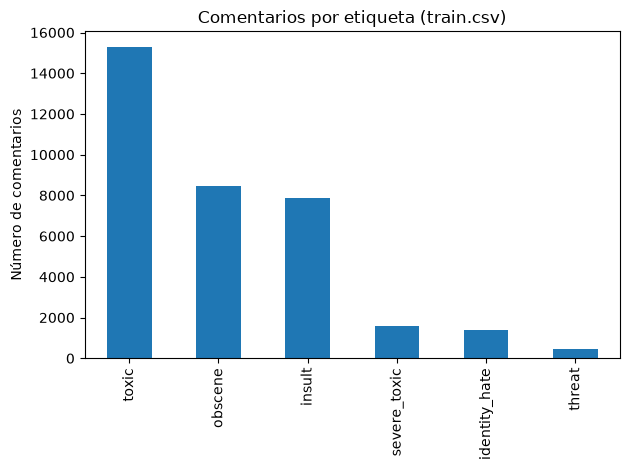

In [5]:
import matplotlib.pyplot as plt

conteo.plot(kind="bar", title="Comentarios por etiqueta (train.csv)")
plt.ylabel("Número de comentarios")
plt.tight_layout()
plt.show()

In [6]:
# Muestra manual para revisar la calidad de las etiquetas
df.sample(30, random_state=42)[["comment_text"] + labels]

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
119105,"Geez, are you forgetful! We've already discus...",0,0,0,0,0,0
131631,Carioca RFA \n\nThanks for your support on my ...,0,0,0,0,0,0
125326,"""\n\n Birthday \n\nNo worries, It's what I do ...",0,0,0,0,0,0
111256,Pseudoscience category? \n\nI'm assuming that ...,0,0,0,0,0,0
83590,"(and if such phrase exists, it would be provid...",0,0,0,0,0,0
37546,", 9 October 2007 (UTC)\n\nP.s, the delta funct...",0,0,0,0,0,0
98371,"]]- 10 September 1910, [[[Couvet]] )",0,0,0,0,0,0
67118,Negro league baseball task-force talk].,0,0,0,0,0,0
129625,List of My Three Sons episodes \n\nI saw you r...,0,0,0,0,0,0
48941,Quoting Loremaster: In order to make sure you ...,0,0,0,0,0,0


In [7]:
# Casi-duplicados: texto en minúsculas y sin espacios extra
norm = df["comment_text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
print("Casi-duplicados:", norm.duplicated().sum())

Casi-duplicados: 258


In [ ]:
import re

for i in [25255, 146861, 96229]:
    texto = re.sub(r"\d+\.\d+\.\d+\.\d+", "[IP]", df.loc[i, "comment_text"])
    print(i, "->", texto)
    print(df.loc[i, labels].to_dict(), "\n")

25255 -> no worries 

We will use another account, and will not stop until wikipedia stops pushing the evil, sin filled gay agenda
{'toxic': 1, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 1} 

146861 -> I see you have such a low self-esteem that you have to warn others not to attack you.4.130.134.233
{'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0} 

96229 -> By the way, who do you think you are, warning me about removing totally unrelated music tracks from a disco-listing? Trust me, you're not the only person on this planet who has been (or still is) involved in disco since the seventies. Get offa that clowd, why don't you? I have done more radio than you ever will, so don't talk to me like I am anti-radio or something.  12:34, 8 Jun 2005 (UTC)
{'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0} 



In [9]:
df["norm"] = norm
d = df[df["norm"].duplicated(keep=False)]
conflictos = (d.groupby("norm")[labels].nunique().max(axis=1) > 1).sum()
print("Grupos de casi-duplicados con etiquetas distintas:", conflictos)

Grupos de casi-duplicados con etiquetas distintas: 41
